# Záření černého tělesa, pokročilá verze: teplota povrchu, tepelný ostrov a sucho z Landsatu 8

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Záření černého tělesa](https://openskylab.space/edu_viz_blackbody_radiation.html) · [English version](blackbody_radiation_pro_en.ipynb)

Pokročilá verze notebooku k Planckovu zákonu. Teplotu povrchu tu z termálního pásma Landsatu 8 počítáš rovnicí přenosu záření, tedy s emisivitou i atmosférou, a zjistíš, která z oprav je důležitější. Výsledek použiješ na tepelný ostrov Prahy ve dvou dnech a na index sucha TVDI z prostoru teplota–NDVI.

**Cíl:** spočítat teplotu povrchu z rovnice přenosu záření a odhadnout vliv emisivity a atmosféry, změřit povrchový tepelný ostrov podle třídy pokryvu a sestavit z prostoru teplota–NDVI suchou a mokrou hranu a index TVDI.

**Data:** Landsat 8 OLI/TIRS Collection 1 Level-1 z veřejného archivu Google Cloud: `LC08_L1TP_191025_20190626_20190705_01_T1` (26. 6. 2019, vlna veder) a `LC08_L1TP_191025_20170519_20170525_01_T1` (19. 5. 2017), pásma B4, B5, B10, BQA a MTL; třídy ESA WorldCover 2021 v200. Výřez 30 × 30 km kolem Prahy, asi 25 MB. Parametry atmosféry (propustnost, zář nahoru a dolů) se nestahují: jsou zadané jako orientační hodnoty a dají se změnit, skutečné hodnoty pro konkrétní den a místo dává například kalkulačka NASA (Barsi a kol. 2005).

**Úkoly:** čtyři. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 65 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a dvě scény

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.windows import from_bounds
from pyproj import Transformer
warnings.filterwarnings("ignore")
C1, C2 = 1.191042e8, 1.4387752e4         # Planckovy konstanty pro λ v µm a zář ve W·m⁻²·sr⁻¹·µm⁻¹
planck = lambda lam, T: C1 / lam**5 / (np.exp(C2 / (lam * T)) - 1)
planck_inv = lambda lam, L: C2 / (lam * np.log(C1 / (lam**5 * L) + 1))

In [3]:
SCENES = {"2019-06-26": "LC08_L1TP_191025_20190626_20190705_01_T1", "2017-05-19": "LC08_L1TP_191025_20170519_20170525_01_T1"}   # ◀ parametr: dvě scény (vlna veder, jaro)
LON, LAT, HALF = 14.45, 50.08, 15000      # ◀ parametr: střed výřezu a jeho poloviční šířka (m)
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2)
x0, y0 = Transformer.from_crs(4326, 32633, always_xy=True).transform(LON, LAT)
x0, y0 = round(x0 / 30) * 30, round(y0 / 30) * 30

def scene_data(scene):
    base = f"https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/191/025/{scene}/{scene}"
    mtl = {k.strip(): v.strip().strip('"') for k, v in (l.split(" = ") for l in requests.get(base + "_MTL.txt", timeout=60).text.splitlines() if " = " in l)}
    out = {"mtl": mtl}
    for b in ["4", "5", "10", "QA"]:
        with rasterio.Env(**ENV), rasterio.open(f"/vsicurl/{base}_B{b}.TIF") as r:
            w = from_bounds(x0 - HALF, y0 - HALF, x0 + HALF, y0 + HALF, r.transform).round_offsets().round_lengths()
            out[b] = r.read(1, window=w).astype(float); out["transform"] = r.window_transform(w)
    sun = np.sin(np.radians(float(mtl["SUN_ELEVATION"])))
    red, nir = [(float(mtl[f"REFLECTANCE_MULT_BAND_{b}"]) * out[str(b)] + float(mtl[f"REFLECTANCE_ADD_BAND_{b}"])) / sun for b in (4, 5)]
    out["ndvi"] = (nir - red) / (nir + red)
    out["L10"] = float(mtl["RADIANCE_MULT_BAND_10"]) * out["10"] + float(mtl["RADIANCE_ADD_BAND_10"])
    out["BT"] = float(mtl["K2_CONSTANT_BAND_10"]) / np.log(float(mtl["K1_CONSTANT_BAND_10"]) / out["L10"] + 1)
    qa = out["QA"].astype(int)
    out["ok"] = ((qa >> 4) & 1 == 0) & ((qa >> 7) & 3 < 3) & (qa > 1)
    return out

S = {day: scene_data(sc) for day, sc in SCENES.items()}
grid = S[next(iter(S))]["transform"]; shape = S[next(iter(S))]["BT"].shape
wc = np.zeros(shape, np.uint8)
with rasterio.Env(**ENV), rasterio.open("/vsicurl/" + WORLDCOVER) as r:
    reproject(rasterio.band(r, 1), wc, dst_transform=grid, dst_crs="EPSG:32633", resampling=Resampling.mode)
CLASSES = {10: "les", 30: "louka", 40: "pole", 50: "zástavba", 80: "voda"}
for day, s in S.items():
    print(f"{day}: {s['mtl']['SCENE_CENTER_TIME'][:8]} UTC, výška Slunce {float(s['mtl']['SUN_ELEVATION']):.1f}°, jasné pixely {s['ok'].mean():.1%}, "
          f"jasová teplota B10 medián {np.median(s['BT'][s['ok']]) - 273.15:.1f} °C")

2019-06-26: 09:50:52 UTC, výška Slunce 59.8°, jasné pixely 99.9%, jasová teplota B10 medián 31.6 °C
2017-05-19: 09:50:28 UTC, výška Slunce 57.0°, jasné pixely 100.0%, jasová teplota B10 medián 26.2 °C


## 2. Teplota povrchu z rovnice přenosu záření

Senzor nad atmosférou měří L = τ · [ε · B(Ts) + (1 − ε) · L↓] + L↑: záření povrchu zeslabené atmosférou, k tomu odraz záření oblohy a záření samotné atmosféry. Rovnici vyřešíme pro Ts. Emisivitu odhadneme z NDVI jako v základní verzi, parametry atmosféry τ, L↑ a L↓ jsou orientační hodnoty pro vlhké letní ovzduší.

In [4]:
LAM10 = 10.9
TAU, L_UP, L_DOWN = 0.80, 1.6, 2.7        # ◀ parametr: propustnost a zář atmosféry nahoru a dolů (W·m⁻²·sr⁻¹·µm⁻¹), orientační léto

def emissivity(ndvi, wc):
    """Emisivita z NDVI podle prahů (Sobrino a kol. 2004), voda podle WorldCoveru."""
    pv = np.clip((ndvi - 0.2) / (0.5 - 0.2), 0, 1) ** 2
    eps = np.where(ndvi < 0.2, 0.97, np.where(ndvi > 0.5, 0.99, 0.97 + 0.02 * pv))
    return np.where(wc == 80, 0.991, eps)

def lst(L, eps, tau=TAU, l_up=L_UP, l_down=L_DOWN):
    """Rovnice přenosu záření: L_senzor = τ · [ε · B(Ts) + (1 − ε) · L↓] + L↑, řešeno pro Ts."""
    B = (L - l_up - tau * (1 - eps) * l_down) / (tau * eps)
    return planck_inv(LAM10, B)

for s in S.values():
    s["eps"] = emissivity(s["ndvi"], wc)
    s["LST_eps"] = lst(s["L10"], s["eps"], tau=1.0, l_up=0.0, l_down=0.0)      # jen emisivita, bez atmosféry
    s["LST"] = lst(s["L10"], s["eps"])
day = next(iter(S)); s = S[day]
rows = {name: {"jasová teplota (°C)": np.median(s["BT"][s["ok"] & (wc == c)]) - 273.15,
               "jen emisivita (°C)": np.median(s["LST_eps"][s["ok"] & (wc == c)]) - 273.15,
               "s atmosférou (°C)": np.median(s["LST"][s["ok"] & (wc == c)]) - 273.15} for c, name in CLASSES.items()}
sens = {tau: np.median(lst(s["L10"], s["eps"], tau=tau)[s["ok"]]) - 273.15 for tau in (0.70, 0.75, 0.80, 0.85, 0.90)}
print(f"{day}: medián LST podle τ:", {k: round(v, 1) for k, v in sens.items()})
pd.DataFrame(rows).T.round(1)

2019-06-26: medián LST podle τ: {0.7: np.float64(45.7), 0.75: np.float64(40.6), 0.8: np.float64(35.9), 0.85: np.float64(31.6), 0.9: np.float64(27.7)}


,jasová teplota (°C),jen emisivita (°C),s atmosférou (°C)
les,31.2,31.8,35.3
louka,32.6,33.2,37.0
pole,30.6,31.2,34.6
zástavba,34.8,36.4,40.4
voda,28.0,28.4,31.3


> **✏️ Úkol 1.** O kolik stupňů posune teplotu oprava o emisivitu a o kolik oprava o atmosféru? Jak moc se medián teploty změní, když τ změníš o 0,05? Co z toho plyne pro přesnost teploty povrchu, když parametry atmosféry pro daný den neznáš?

*Tvoje odpověď:* 

## 3. Povrchový tepelný ostrov

Porovnáme teplotu povrchu zástavby s okolní zemědělskou krajinou a lesem ve dvou dnech. Pro oba dny tu používáme stejné parametry atmosféry, což je zjednodušení: v květnu 2017 bylo ovzduší jiné než ve vlně veder 2019.

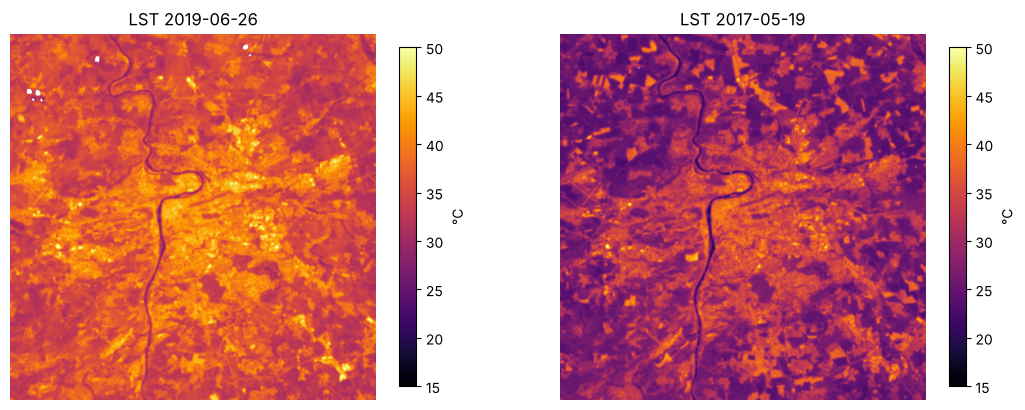

,2019-06-26,2017-05-19
les,35.3,28.9
louka,37.0,29.9
pole,34.6,26.0
zástavba,40.4,34.6
voda,31.3,24.6
tepelný ostrov: zástavba − pole,5.8,8.6
tepelný ostrov: zástavba − les,5.1,5.7


In [5]:
fig, ax = plt.subplots(1, len(S), figsize=(6.5 * len(S), 5.5))
rows = {}
for a, (day, s) in zip(ax, S.items()):
    im = a.imshow(np.where(s["ok"], s["LST"] - 273.15, np.nan), cmap="inferno", vmin=15, vmax=50); a.set_title(f"LST {day}"); a.axis("off")
    fig.colorbar(im, ax=a, shrink=0.8, label="°C")
    med = {name: np.median(s["LST"][s["ok"] & (wc == c)]) - 273.15 for c, name in CLASSES.items()}
    med["tepelný ostrov: zástavba − pole"] = med["zástavba"] - med["pole"]
    med["tepelný ostrov: zástavba − les"] = med["zástavba"] - med["les"]
    rows[day] = med
plt.show()
pd.DataFrame(rows).round(1)

> **✏️ Úkol 2.** Ve kterém dni je rozdíl mezi zástavbou a poli větší a proč, když vlna veder byla v červnu 2019? Proč se rozdíl zástavby a lesa mezi dny mění méně? Jak by se tepelný ostrov změnil v noci (vzpomeň na tepelnou setrvačnost)?

*Tvoje odpověď:* 

## 4. Prostor teplota–NDVI a index sucha TVDI

V grafu teploty povrchu proti NDVI tvoří pixely trojúhelník nebo lichoběžník. Horní, suchá hrana spojuje nejteplejší pixely pro každé NDVI (povrchy bez vody k výparu), dolní, mokrá hrana nejchladnější. TVDI = (Ts − Ts_mokrá) / (Ts_suchá(NDVI) − Ts_mokrá) leží mezi 0 (vlhko) a 1 (sucho) (Sandholt a kol. 2002). Počítáme ho pro louky a pole.

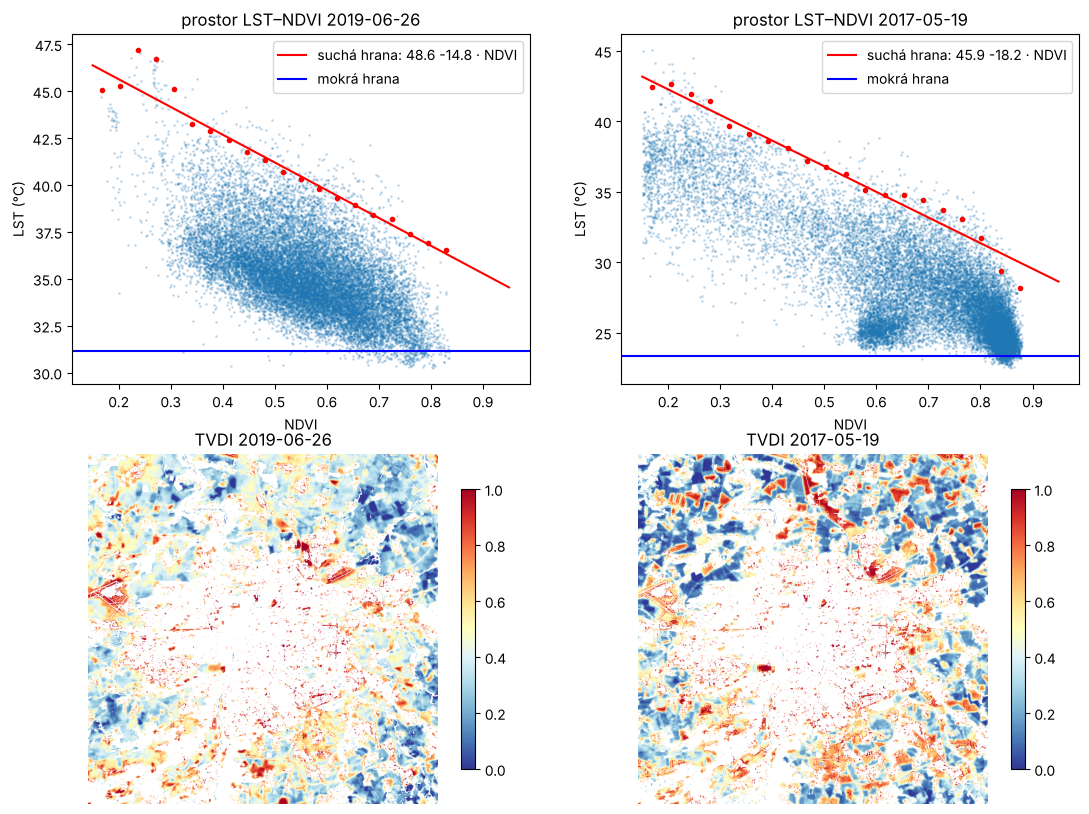

,2019-06-26,2017-05-19
louka,0.64,0.63
pole,0.38,0.31
sklon suché hrany (K na 1 NDVI),-14.79,-18.18


In [6]:
NBINS = 20                                 # ◀ parametr: počet tříd NDVI pro hledání suché hrany
land = np.isin(wc, [30, 40])                # louky a pole: TVDI se používá hlavně pro zemědělskou krajinu

def tvdi(s):
    m = s["ok"] & land & (s["ndvi"] > 0.15)
    nd, ts = s["ndvi"][m], s["LST"][m]
    edges = np.linspace(0.15, nd.max(), NBINS + 1); k = np.digitize(nd, edges)
    mid = np.array([(edges[i - 1] + edges[i]) / 2 for i in range(1, NBINS + 1) if (k == i).sum() > 30])
    tmax = np.array([np.percentile(ts[k == i], 99) for i in range(1, NBINS + 1) if (k == i).sum() > 30])
    b, a = np.polyfit(mid[mid > 0.3], tmax[mid > 0.3], 1)        # suchá hrana Ts_max = a + b · NDVI
    t_wet = np.percentile(ts, 1)                                   # mokrá hrana
    out = np.where(m, (s["LST"] - t_wet) / (a + b * s["ndvi"] - t_wet), np.nan)
    return np.clip(out, 0, 1), (a, b, t_wet, mid, tmax, nd, ts)

fig, ax = plt.subplots(2, len(S), figsize=(6.5 * len(S), 10))
summary = {}
rng = np.random.default_rng(0)
for j, (day, s) in enumerate(S.items()):
    s["TVDI"], (a, b, t_wet, mid, tmax, nd, ts) = tvdi(s)
    sel = rng.choice(len(nd), min(20000, len(nd)), replace=False)
    ax[0, j].scatter(nd[sel], ts[sel] - 273.15, s=1, alpha=0.2)
    xx = np.linspace(0.15, 0.95, 10)
    ax[0, j].plot(xx, a + b * xx - 273.15, "r", label=f"suchá hrana: {a - 273.15:.1f} {b:+.1f} · NDVI")
    ax[0, j].axhline(t_wet - 273.15, color="b", label="mokrá hrana"); ax[0, j].plot(mid, tmax - 273.15, "ro", ms=3)
    ax[0, j].set(xlabel="NDVI", ylabel="LST (°C)", title=f"prostor LST–NDVI {day}"); ax[0, j].legend()
    im = ax[1, j].imshow(s["TVDI"], cmap="RdYlBu_r", vmin=0, vmax=1); ax[1, j].set_title(f"TVDI {day}"); ax[1, j].axis("off")
    fig.colorbar(im, ax=ax[1, j], shrink=0.8)
    summary[day] = {name: np.nanmedian(s["TVDI"][wc == c]) for c, name in CLASSES.items() if c in (30, 40)} | {"sklon suché hrany (K na 1 NDVI)": b}
plt.show()
pd.DataFrame(summary).round(2)

> **✏️ Úkol 3.** Proč má suchá hrana záporný sklon, tj. proč jsou suché pixely s vyšším NDVI chladnější? Ve kterém dni vychází pole sušší a odpovídá to tomu, co víš o jaru 2017 a vlně veder 2019? Proč nelze TVDI dvou dnů srovnávat přímo, když se hrany počítají pro každý snímek zvlášť?

*Tvoje odpověď:* 

> **✏️ Úkol 4.** Louky vycházejí v TVDI sušší než pole. Podívej se v mapě, kde louky podle WorldCoveru leží (městské trávníky, suché svahy, okraje zástavby). Které předpoklady metody (stejné počasí v celém výřezu, jen rozdíly ve vlhkosti, ne v drsnosti a nadmořské výšce) tu mohou neplatit? Změň `NBINS` a sleduj, jak citlivá je suchá hrana.

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Najdi v kalkulačce NASA (atmcorr.gsfc.nasa.gov) parametry atmosféry pro Prahu a oba dny, vlož je místo orientačních hodnot (pro každý den zvlášť) a porovnej teploty a tepelný ostrov.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Landsat 8 OLI/TIRS Collection 1 Level-1, U.S. Geological Survey; veřejný archiv Google Cloud (`gcp-public-data-landsat`). Data USGS jsou bez omezení užití, s uvedením zdroje.
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- USGS (2019). *Landsat 8 (L8) Data Users Handbook*, verze 5.0, kap. 5.
- Sobrino, J. A., Jiménez-Muñoz, J. C., Paolini, L. (2004). Land surface temperature retrieval from LANDSAT TM 5. *Remote Sensing of Environment* 90, 434–440. https://doi.org/10.1016/j.rse.2004.02.003
- Barsi, J. A., Schott, J. R., Palluconi, F. D., Hook, S. J. (2005). Validation of a web-based atmospheric correction tool for single thermal band instruments. *Proc. SPIE* 5882, 58820E. https://doi.org/10.1117/12.619990
- Sandholt, I., Rasmussen, K., Andersen, J. (2002). A simple interpretation of the surface temperature/vegetation index space for assessment of surface moisture status. *Remote Sensing of Environment* 79, 213–224. https://doi.org/10.1016/S0034-4257(01)00274-7

### Jak citovat

OpenSkyLab (2026). Záření černého tělesa, pokročilá verze: teplota povrchu, tepelný ostrov a sucho z Landsatu 8 [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*